## ML Practical/Lab 2
## Name: Akshay Tripathi
## Roll no:C-C1-16


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [2]:
df=pd.read_csv("USA_Housing.csv")
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [3]:
df.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316
4999,65510.581804,5.992305,6.792336,4.07,46501.283803,1.298950e+06,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [4]:
df.shape

(5000, 7)

In [5]:
df.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [7]:
df.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [8]:
df.isnull().sum()

,0
Avg. Area Income,0
Avg. Area House Age,0
Avg. Area Number of Rooms,0
Avg. Area Number of Bedrooms,0
Area Population,0
Price,0
Address,0


In [9]:
df.duplicated().sum()

np.int64(0)

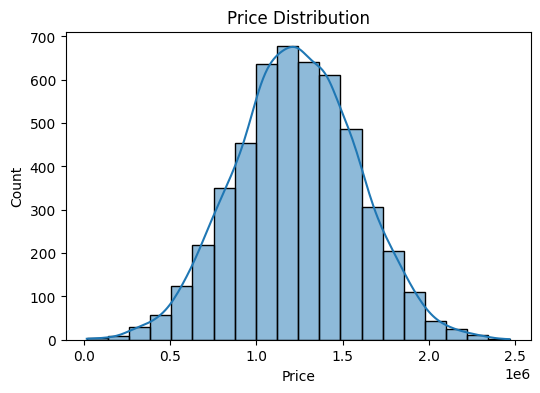

In [10]:
#univarient analysis
plt.figure(figsize=(6,4))
sns.histplot(df["Price"],bins=20,kde=True)

plt.title("Price Distribution")
plt.show()

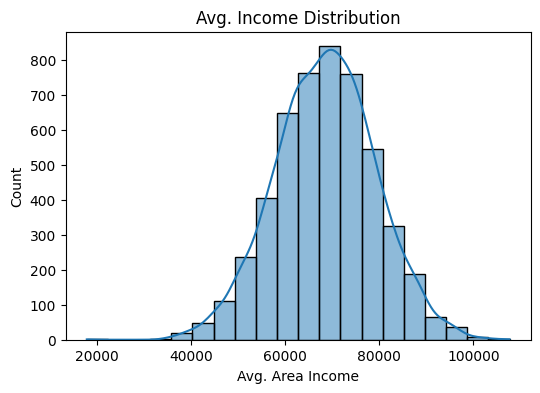

In [11]:
plt.figure(figsize=(6,4))
sns.histplot(df["Avg. Area Income"],bins=20,kde=True)

plt.title("Avg. Income Distribution")
plt.show()

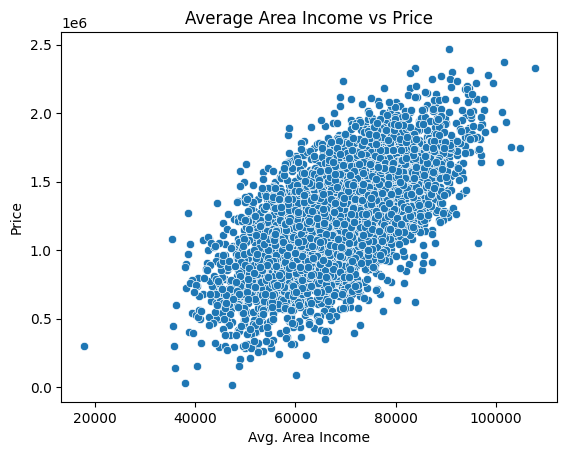

In [12]:
sns.scatterplot(x="Avg. Area Income", y="Price", data=df)
plt.title("Average Area Income vs Price")
plt.show()

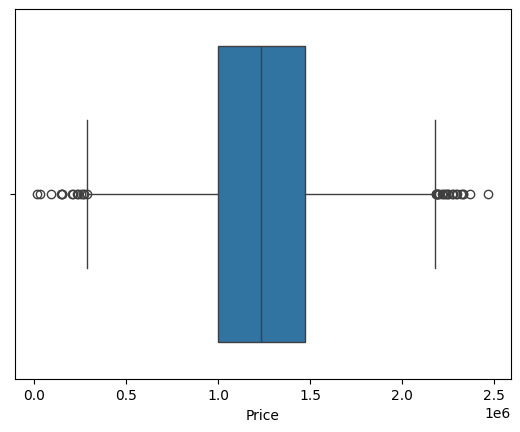

In [13]:
sns.boxplot(x=df["Price"])
plt.show()

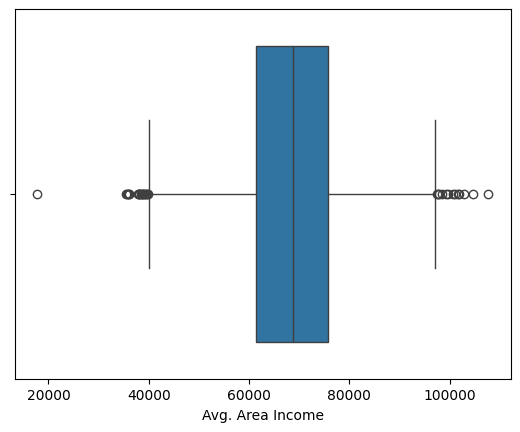

In [14]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

In [15]:
Q1=df["Price"].quantile(0.25)
Q3=df["Price"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

df=df[(df["Price"]>=lower) & (df["Price"]<=upper)]

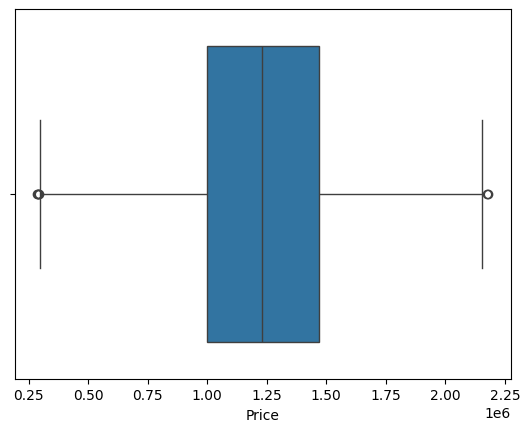

In [16]:
sns.boxplot(x=df["Price"])
plt.show()

In [17]:
Q1=df["Avg. Area Income"].quantile(0.25)
Q3=df["Avg. Area Income"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR

df=df[(df["Avg. Area Income"]>=lower) & (df["Avg. Area Income"]<=upper)]

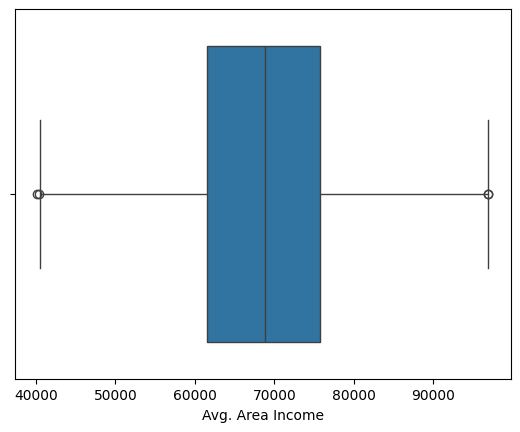

In [18]:
sns.boxplot(x=df["Avg. Area Income"])
plt.show()

In [19]:
df.drop("Address",axis=1,inplace=True)

In [20]:
pd.set_option('display.float_format','{:.2f}'.format)

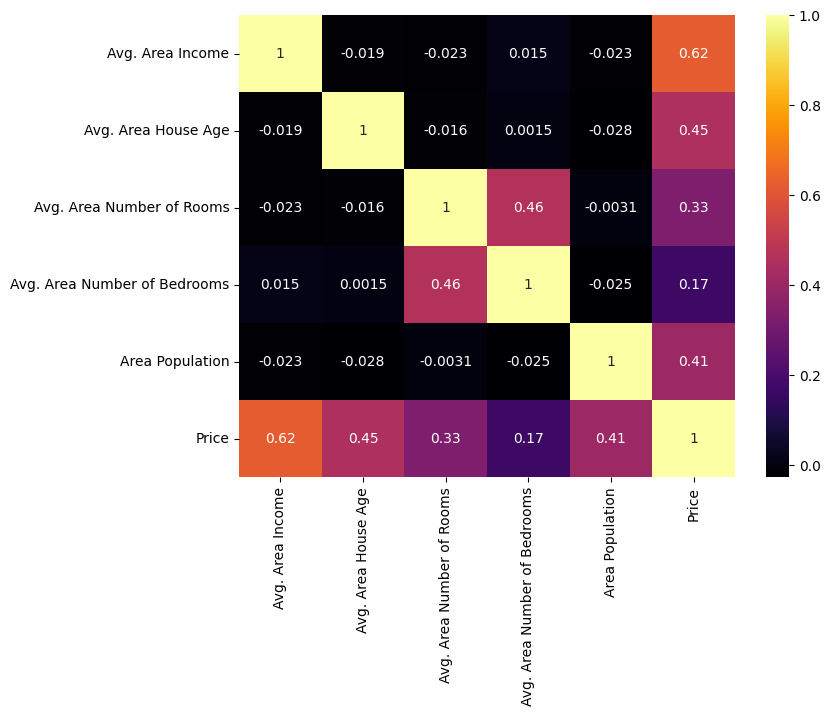

In [21]:
#multivarient
plt.figure(figsize=(8,6))
numeric_df=df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(),
                    annot=True,
                    cmap='inferno')
plt.show()

## SLR

In [22]:
#SLR
X = df[['Avg. Area Income']]
y = df['Price']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [24]:
slr_model=LinearRegression()
slr_model.fit(X_train,y_train)

LinearRegression()

In [25]:
y_pred=slr_model.predict(X_test)

In [26]:
from sklearn import metrics
from sklearn.metrics import mean_absolute_error  #accuracy is given by r2 score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2): {r2:.4f}")

Mean Absolute Error (MAE): 209409.30
Mean Squared Error (MSE): 66978557287.98
Root Mean Squared Error (RMSE): 258802.16
R-squared Score (R2): 0.4291


In [27]:
print("Intercept:",slr_model.intercept_)
print("Slope:",slr_model.coef_[0])

Intercept: -155455.2824973939
Slope: 20.250537400684834


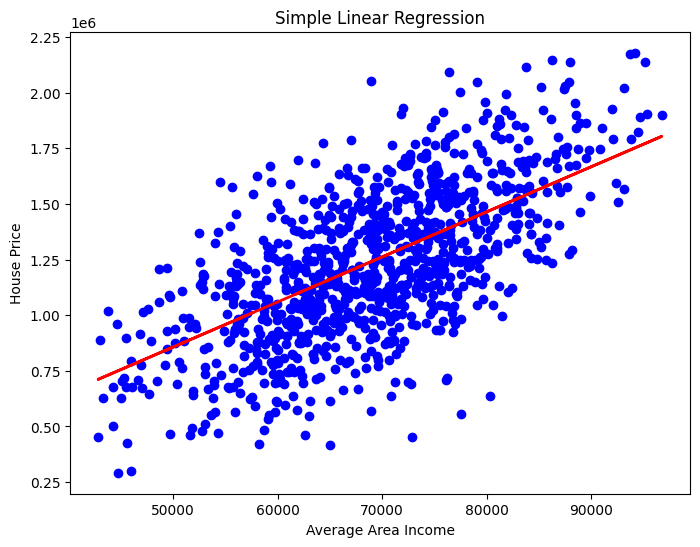

In [28]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,color='blue',label='Actual Data')
plt.plot(X_test,y_pred,color='red',linewidth=2,label='Regression Line')

plt.xlabel("Average Area Income")
plt.ylabel("House Price")
plt.title("Simple Linear Regression")
plt.show()

In [29]:
income = float(input("Enter Average Area Income: "))
new_data = [[income]]
prediction = slr_model.predict(new_data)
print(f"Predicted House Price = ${prediction[0]:,.2f}")

Enter Average Area Income: 65000
Predicted House Price = $1,160,829.65


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


## MLR

In [30]:
# Features and target
X = df[['Avg. Area Income',
        'Avg. Area House Age',
        'Avg. Area Number of Rooms',
        'Avg. Area Number of Bedrooms',
        'Area Population']]
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

LinearRegression()

In [31]:
income = float(input("Enter Average Area Income: "))
house_age = float(input("Enter Average Area House Age: "))
rooms = float(input("Enter Average Area Number of Rooms: "))
bedrooms = float(input("Enter Average Area Number of Bedrooms: "))
population = float(input("Enter Area Population: "))

new_data = [[income, house_age, rooms, bedrooms, population]]

prediction = mlr_model.predict(new_data)

print(f"Predicted House Price = ${prediction[0]:,.2f}")

Enter Average Area Income: 65000
Enter Average Area House Age: 5
Enter Average Area Number of Rooms: 3
Enter Average Area Number of Bedrooms: 2
Enter Area Population: 12345
Predicted House Price = $151,608.74


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Hyperparameter Tuning

In [32]:
#hyperparameter is a configuration setting used to control the training process, such as the learning rate, batch size, and number of hidden layers

## Ridge Regression

In [33]:
from sklearn.model_selection import GridSearchCV


In [34]:
from sklearn.linear_model import Ridge
ridge=Ridge()
ridge.fit(X_train, y_train)
ridge_pred=ridge.predict(X_test)
print("Default Ridge R2:",r2_score(y_test,ridge_pred))

Default Ridge R2: 0.914832076303878


In [35]:
param_grid={'alpha':[0.001,0.01,0.1,1,10,100]}

In [36]:
grid_ridge=GridSearchCV(estimator=Ridge(),param_grid=param_grid,scoring='r2',cv=5)

In [37]:
grid_ridge.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='r2')

In [38]:
print("Best Alpha: ",grid_ridge.best_params_)

Best Alpha:  {'alpha': 1}


In [39]:
print(grid_ridge.best_score_)

0.9121212051696581


In [40]:
best_ridge=grid_ridge.best_estimator_
ridge_pred=best_ridge.predict(X_test)

In [41]:
mae = mean_absolute_error(y_test, ridge_pred)
mse = mean_squared_error(y_test, ridge_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, ridge_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2): {r2:.8f}")

Mean Absolute Error (MAE): 79277.25
Mean Squared Error (MSE): 9992756317.46
Root Mean Squared Error (RMSE): 99963.78
R-squared Score (R2): 0.91483208
